In [1]:
print('In the name of Allah')

In the name of Allah


In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set default styles for our plots
sns.set_theme()

## **Problem 1: House Price Prediction using Gradient Descent**

Dataset:

[<u>House Prices Dataset (Kaggle)</u>](https://www.kaggle.com/datasets/yasserh/housing-prices-dataset?utm_source=chatgpt.com)

### **Tasks**

1.  Load the dataset using Pandas.

2.  Select one feature (e.g., area) and the target variable (price). And convert them to numpy array

3.  Implement the Mean Squared Error (MSE) Cost Function manually.

4.  Calculate the initial cost using random values of slope and intercept.

5.  Apply Gradient Descent from scratch.

6.  Train for 1000 iterations.

7.  Plot:

    - Iteration vs Cost

    - Actual vs Predicted Values

8.  Report the final learned parameters.






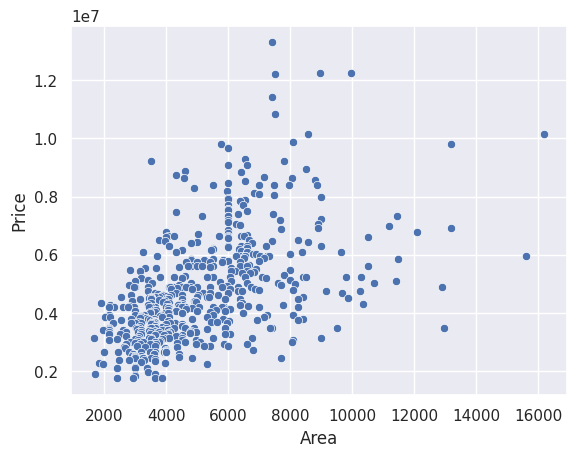

In [85]:
from sklearn.preprocessing import StandardScaler, RobustScaler

df = pd.read_csv('Housing.csv')

df

X = df['area'].values
y = df['price'].values

# print(X.info())
# ss = StandardScaler()
# rs = RobustScaler()

# X = rs.fit_transform(X).ravel()
# y = ss.fit_transform(y).ravel()

sns.scatterplot(x = X, y = y)

plt.xlabel('Area')
plt.ylabel('Price')
plt.show()

In [86]:
# y.describe()

In [87]:
def make_prediction( X, y, w, b ) :
  """Calculates the model output: f(x) = wx + b"""

  m = X.shape[0]
  pred_list = np.zeros((m,))

  for i in range(m) :
    pred_list[i] = w * X[i] + b

  return pred_list

In [88]:
def compute_cost( X, y, w, b ) :

  """Calculates the Mean Squared Error (MSE) to measure model accuracy"""

  m = X.shape[0]
  cost = 0.0

  for i in range( m ) :

    prediction = w * X[i] + b
    error = prediction - y[i]

    error_squared = error ** 2

    cost = cost + error_squared

  cost = cost / ( 2 * m )

  return cost


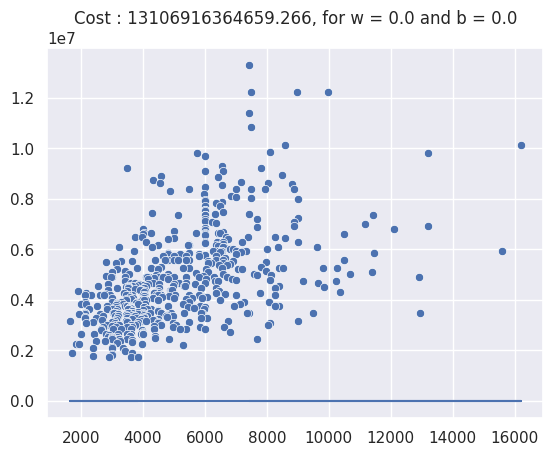

In [89]:
w = 0.0
b = 0.0

predictions = make_prediction( X, y, w = w, b = b )

sns.scatterplot( x = X, y = y )
plt.plot(X, predictions)

# The title shows the cost, helping us see how 'wrong' our line is

plt.title(f'Cost : {compute_cost(X, y, w = w, b = b)}, for w = {w} and b = {b}')
plt.show()


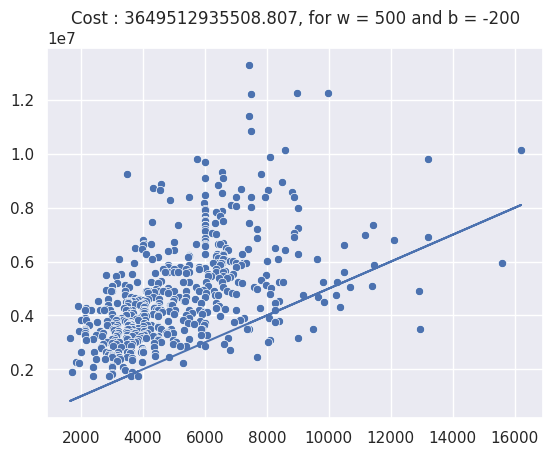

In [90]:
w = 500
b = -200

predictions = make_prediction( X, y, w = w, b = b )

sns.scatterplot( x = X, y = y )
plt.plot(X, predictions)

# The title shows the cost, helping us see how 'wrong' our line is

plt.title(f'Cost : {compute_cost(X, y, w = w, b = b)}, for w = {w} and b = {b}')
plt.show()

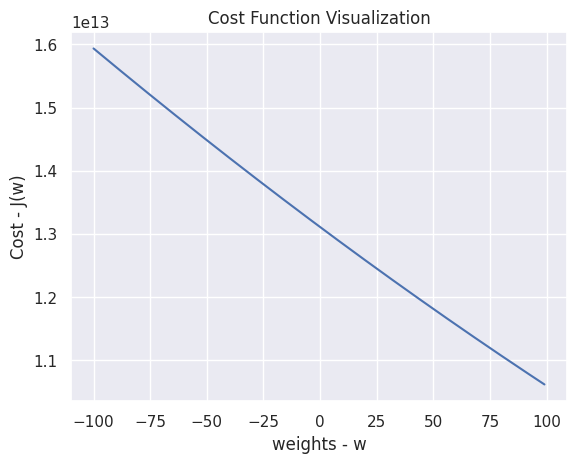

In [91]:
w_range = []
cost_history = []

# Loop through different weight values to see how they affect the cost

for i in range(-100, 100):
    cost_i = compute_cost(X, y, w=i, b=0)
    w_range.append(i)
    cost_history.append(cost_i)

# Plotting the Cost Function: The goal of ML is to find the bottom of this 'U'

plt.plot(w_range, cost_history)
plt.xlabel("weights - w")
plt.ylabel("Cost - J(w)")
plt.title("Cost Function Visualization")

plt.show()

In [92]:
# Gradient Descent

def calculate_gradient( X, y, w, b ) :

  """Computes the Gradient (Direction to move) for w and b"""

  m = X.shape[0]

  dj_dw = 0.0
  dj_db = 0.0

  for i in range(m) :

    prediction = w * X[i] + b
    error = prediction - y[i]

    dj_dw = dj_dw + ( error * X[i] )

    dj_db = dj_db + error

  return dj_dw / m, dj_db / m


In [93]:
calculate_gradient( X, y, w = 1500, b = 100 )

(np.float64(20121014414.12844), np.float64(2959182.6788990824))

In [94]:
def gradient_descent( X, y, w_input, b_input, max_iter, alpha ) :

  """Automates the tuning of w and b to minimize cost"""

  w = w_input
  b = b_input

  cost_memo = []
  iteration = []

  for i in range(max_iter) :

    dj_dw, dj_db = calculate_gradient( X, y, w, b )

    w = w - alpha * dj_dw
    b = b - alpha * dj_db

    cost = compute_cost( X, y, w, b )
    cost_memo.append(cost)
    iteration.append(i)

    if i % 100 == 0 :
      print( f'Iteration : {i}, w : {w:0.4f}, b : {b:0.4f}, dj_dw : {dj_dw:0.4f}, dj_db : {dj_db:0.4f}, cost : {cost:0.4f}' )

  return w, b, cost_memo, iteration

In [95]:
w_final, b_final, cost_memo, iter_list = gradient_descent( X, y, w_input = 0, b_input = 0, max_iter = 1001, alpha = 0.00000001 )

Iteration : 0, w : 267.2292, b : 0.0477, dj_dw : -26722920050.0917, dj_db : -4766729.2477, cost : 7080823741993.8369
Iteration : 100, w : 855.7099, b : 0.5041, dj_dw : 59.2686, dj_db : -359359.7383, cost : 1673381895292.8865
Iteration : 200, w : 855.7098, b : 0.8634, dj_dw : 59.2686, dj_db : -359359.6842, cost : 1673381766153.4792
Iteration : 300, w : 855.7098, b : 1.2228, dj_dw : 59.2686, dj_db : -359359.6301, cost : 1673381637014.1155
Iteration : 400, w : 855.7097, b : 1.5822, dj_dw : 59.2686, dj_db : -359359.5760, cost : 1673381507874.7869
Iteration : 500, w : 855.7096, b : 1.9415, dj_dw : 59.2686, dj_db : -359359.5219, cost : 1673381378735.4978
Iteration : 600, w : 855.7096, b : 2.3009, dj_dw : 59.2686, dj_db : -359359.4678, cost : 1673381249596.2485
Iteration : 700, w : 855.7095, b : 2.6602, dj_dw : 59.2686, dj_db : -359359.4137, cost : 1673381120457.0378
Iteration : 800, w : 855.7095, b : 3.0196, dj_dw : 59.2686, dj_db : -359359.3597, cost : 1673380991317.8647
Iteration : 900, w 

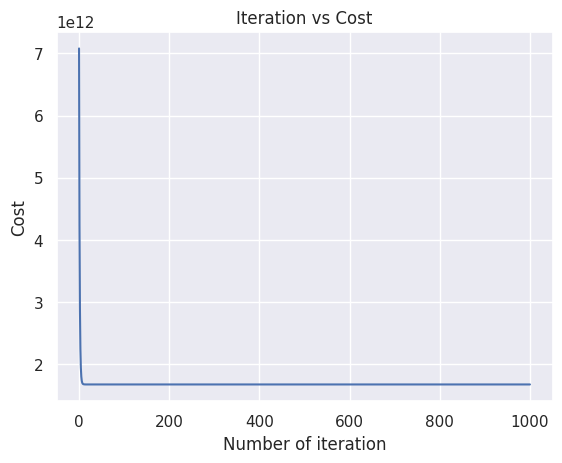

In [96]:
# Iteration vs Cost plot

plt.plot(iter_list, cost_memo)

plt.xlabel('Number of iteration')
plt.ylabel('Cost')
plt.title('Iteration vs Cost')
plt.show()

Optimized w: 855.7093, b: 3.7383


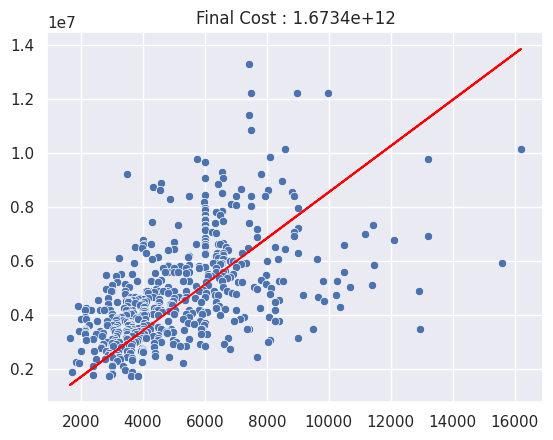

In [97]:
# Actual vs Predicted Values

print(f"Optimized w: {w_final:0.4f}, b: {b_final:0.4f}")

final_preds = make_prediction( X, y, w = w_final, b = b_final )

sns.scatterplot(x = X, y = y)

plt.plot(X ,final_preds, color = 'red', label = 'Best Fit Line')
plt.title(f'Final Cost : {compute_cost(X, y, w = w_final, b = b_final):0.4e}')
plt.show()

In [98]:
# Final Learned Parameters

print(f'Final w(slope) : {w_final}')
print(f'Final b(intercept) : {b_final}')


Final w(slope) : 855.7093352124035
Final b(intercept) : 3.7383197159289154


## **Problem 2: Student Performance Prediction**

**Dataset:  **
[<u>Student Performance Dataset</u>](https://www.kaggle.com/datasets/spscientist/students-performance-in-exams?utm_source=chatgpt.com)

### **Tasks**

1.  Predict math score using reading score. convert them to numpy array from the dataframe

2.  Implement the MSE Cost Function manually.

3.  Compute the gradient formulas manually.

4.  Perform Gradient Descent for 500 iterations.

5.  Print the cost after every 50 iterations.

6.  Plot Cost vs Iteration.

In [99]:
df = pd.read_csv('StudentsPerformance.csv')

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


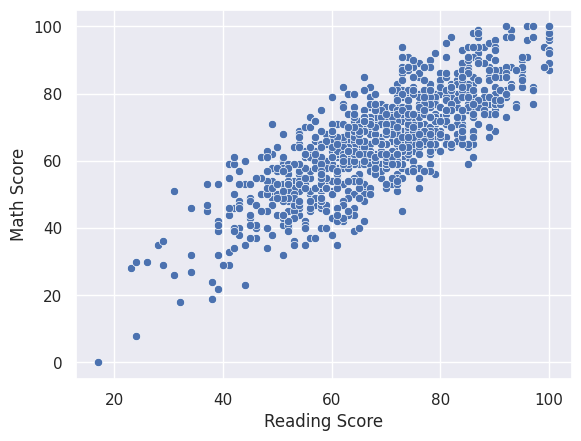

In [100]:
X = df['reading score'].values
y = df['math score'].values

sns.scatterplot(x = X, y = y)

plt.xlabel('Reading Score')
plt.ylabel('Math Score')
plt.show()

In [101]:
# Predicted Function

def make_prediction( X, y, w, b ) :

  """Calculates the Model Output : f(x) = wx + b"""

  m = X.shape[0]
  pred_list = np.zeros((m,))

  for i in range(m) :
    pred_list[i] = w * X[i] + b

  return pred_list


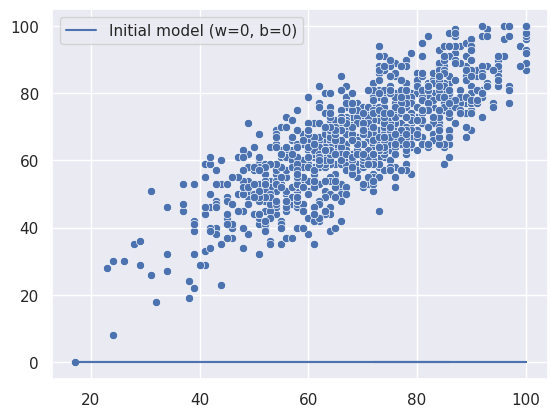

In [102]:
predictions = make_prediction(X, y, 0, 0)

sns.scatterplot(x = X, y = y)
plt.plot(X, predictions, label='Initial model (w=0, b=0)')
plt.legend()
plt.show()

/tmp/ipykernel_1239/643373126.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


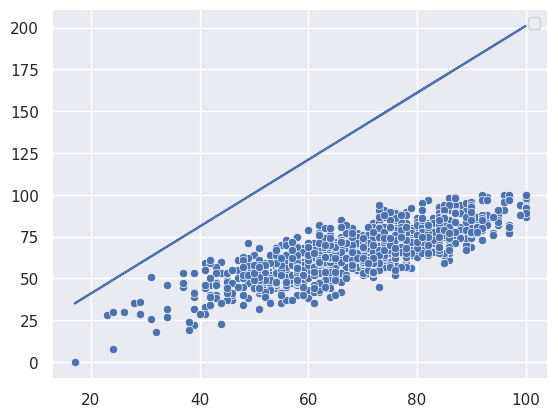

In [103]:
predictions = make_prediction(X, y, 2, 1)

sns.scatterplot(x = X, y = y)
plt.plot(X, predictions)
plt.legend()
plt.show()

/tmp/ipykernel_1239/3720480074.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


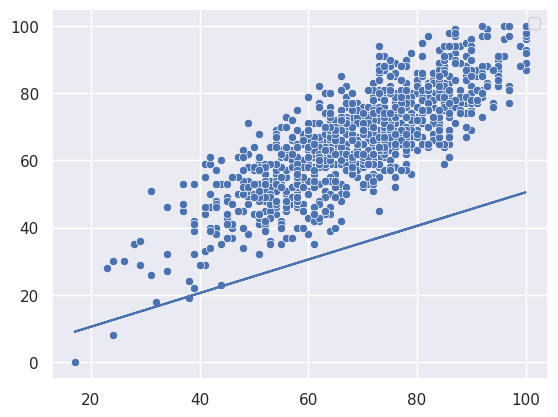

In [104]:
predictions = make_prediction(X, y, .5, .5)

sns.scatterplot(x = X, y = y)
plt.plot(X, predictions)
plt.legend()
plt.show()

In [105]:
# MSE Cost Function

def compute_cost( X, y, w, b ) :

  """Calculates the Mean Squared Error (MSE) to measure model accuracy"""

  m = X.shape[0]
  cost = 0.0

  for i in range( m ) :

    prediction = w * X[i] + b
    error = prediction - y[i]

    error_squared = error ** 2

    cost = cost + error_squared

    cost = cost / ( 2 * m )

  return cost


In [106]:
# Gradient Descent

def calculate_gradient( X, y, w, b ) :

  """Computes the gradient (direction to move) for w and b"""

  m = X.shape[0]

  dj_dw = 0.0
  dj_db = 0.0

  for i in range( m ) :

    prediction = w * X[i] + b
    error = prediction - y[i]

    dj_dw = dj_dw + ( error * X[i] )

    # The bias gradient is just the sum of errors

    dj_db = dj_db + error

  return dj_dw / m, dj_db / m


In [107]:
calculate_gradient( X, y, w = 5, b = 2 )

(np.float64(20372.725), np.float64(281.756))

In [108]:
def gradient_descent( X, y, w_input, b_input, max_iter, alpha ) :

  """Automates the tuning of w and b to minimize cost"""

  w = w_input
  b = b_input

  cost_memo = []
  iteration = []

  for i in range(max_iter) :

    dj_dw, dj_db = calculate_gradient( X, y, w, b )

    w = w - alpha * dj_dw
    b = b - alpha * dj_db

    cost = compute_cost( X, y, w, b )

    cost_memo.append(cost)
    iteration.append(i)

    if i % 50 == 0:
      print(f'Iteration : {i}, w : {w:0.4f}, b : {b:0.4f}, dj_dw : {dj_dw:0.4f}, dj_db : {dj_db:0.4f}, cost : {cost:0.4f}')

  return w, b, cost_memo, iteration



In [27]:
w_final, b_final, cost_memo, iteration = gradient_descent( X, y, w_input = 0, b_input = 0, max_iter = 501, alpha = 0.0001 )

Iteration : 0, w : 0.4752, b : 0.0066, dj_dw : -4752.1280, dj_db : -66.0890, cost : 0.6528
Iteration : 50, w : 0.9507, b : 0.0148, dj_dw : 0.0043, dj_db : -0.3128, cost : 0.0114
Iteration : 100, w : 0.9507, b : 0.0163, dj_dw : 0.0043, dj_db : -0.3128, cost : 0.0114
Iteration : 150, w : 0.9507, b : 0.0179, dj_dw : 0.0043, dj_db : -0.3127, cost : 0.0114
Iteration : 200, w : 0.9507, b : 0.0194, dj_dw : 0.0043, dj_db : -0.3126, cost : 0.0114
Iteration : 250, w : 0.9506, b : 0.0210, dj_dw : 0.0043, dj_db : -0.3126, cost : 0.0114
Iteration : 300, w : 0.9506, b : 0.0226, dj_dw : 0.0043, dj_db : -0.3125, cost : 0.0114
Iteration : 350, w : 0.9506, b : 0.0241, dj_dw : 0.0043, dj_db : -0.3124, cost : 0.0114
Iteration : 400, w : 0.9506, b : 0.0257, dj_dw : 0.0043, dj_db : -0.3124, cost : 0.0114
Iteration : 450, w : 0.9506, b : 0.0273, dj_dw : 0.0043, dj_db : -0.3123, cost : 0.0114
Iteration : 500, w : 0.9505, b : 0.0288, dj_dw : 0.0043, dj_db : -0.3122, cost : 0.0114


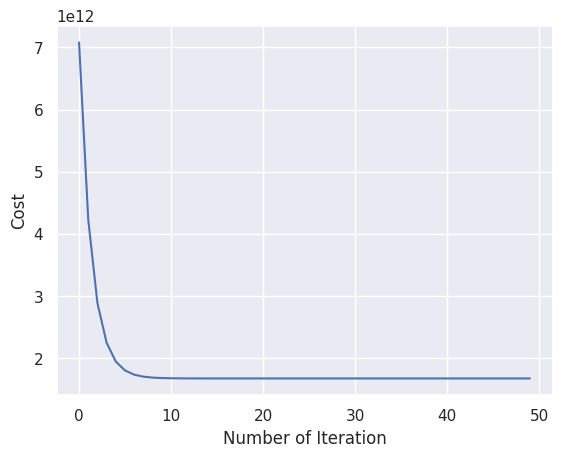

In [109]:
# Plot Cost vs Iteration.

plt.plot( iteration[:50], cost_memo[:50] )
plt.xlabel("Number of Iteration")
plt.ylabel('Cost')
plt.show()

## **Problem 3: Insurance Charges Prediction**

**Dataset:  **
[<u>Medical Cost Personal Dataset</u>](https://www.kaggle.com/datasets/mirichoi0218/insurance?utm_source=chatgpt.com)

### **Tasks**

1.  Use age as input feature.

2.  Use charges as target.

3.  Convert them to numpy array from the dataframe

4.  Implement:

    - Cost Function

    - Gradient Calculation

    - Gradient Descent

5.  Train for 1000 iterations.

6.  Compare initial and final costs.

7.  Visualize the regression line.

In [110]:
df = pd.read_csv('insurance.csv')

# df.info()

X = df['age'].values
y = df['charges'].values

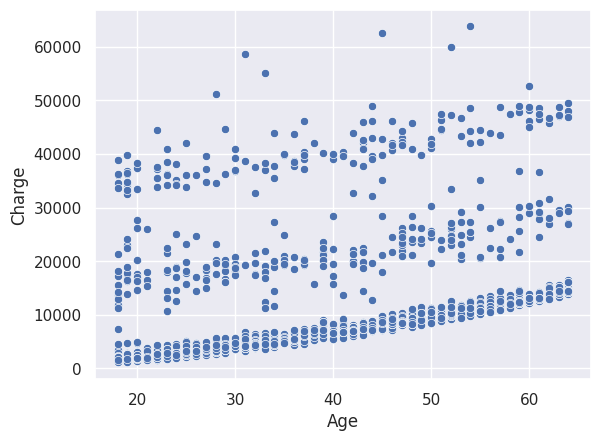

In [111]:
sns.scatterplot(x = X, y = y)

plt.xlabel('Age')
plt.ylabel('Charge')
plt.show()

In [112]:
def compute_cost( X, y, w, b ) :

  """Calculate the Mean Squared Error(MSE) to measure model accuracy"""

  m = len(X)
  cost = 0.0

  for i in range(m) :

    prediction = w * X[i] + b
    error = prediction - y[i]

    error_squared = error ** 2

    cost = cost + error_squared

  cost = cost / ( 2 * m )

  return cost


In [113]:
# Gradient Calculation
def calculate_gradient( X, y, w, b ) :

  """Computes the gradient (direction to move) for w and b"""

  m = X.shape[0]

  dj_dw = 0.0
  dj_db = 0.0

  for i in range( m ) :

    prediction = w * X[i] + b
    error = prediction - y[i]

    dj_dw = dj_dw + ( error * X[i] )

    dj_db = dj_db + error

  return dj_dw / m, dj_db / m


In [114]:
def gradient_descent( X, y, w_input, b_input, max_iter, alpha ) :

  """Automates the tuning of w and b to minimize cost"""

  w = w_input
  b = b_input

  cost_memo = []
  iteration = []

  for i in range(max_iter) :

    dj_dw, dj_db = calculate_gradient( X, y, w, b )

    w = w - alpha * dj_dw
    b = b - alpha * dj_db

    cost = compute_cost(X, y, w, b)

    cost_memo.append(cost)
    iteration.append(i)

  return w, b, cost_memo, iteration


In [115]:
w_final, b_final, cost_memo, iter_list = gradient_descent( X, y, w_input = 0, b_input = 0, max_iter = 1001, alpha = 0.001 )

In [116]:
initial_cost = cost_memo[0]
final_cost = cost_memo[-1]

print(f"Initial Cost : {initial_cost : 0.4f}")
print(f"Final Cost   : {final_cost : 0.4f}")
print(f"Reduction    : {initial_cost - final_cost : 0.4f}")

Initial Cost :  118133817.9010
Final Cost   :  67172288.4111
Reduction    :  50961529.4898


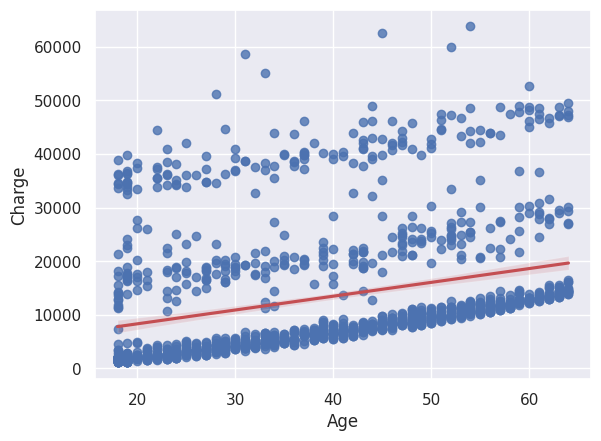

In [117]:
sns.regplot( x = X, y = y, line_kws=dict(color="r") )

plt.xlabel('Age')
plt.ylabel('Charge')
plt.show()

## **Problem 4: Salary Prediction**

**Dataset:  **
[<u>Salary Dataset</u>](https://www.kaggle.com/datasets/karthickveerakumar/salary-data-simple-linear-regression?utm_source=chatgpt.com)

### **Tasks**

1.  Predict Salary from YearsExperience.

2.  Initialize parameters randomly.

3.  Calculate cost before training.

4.  Apply Gradient Descent.

5.  Plot:

    - Cost vs Iteration

    - Regression Line

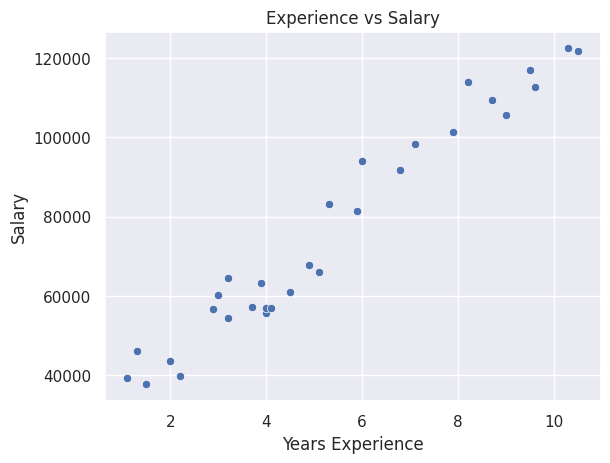

In [118]:
df = pd.read_csv('Salary_Data.csv')

# df.info()

X = df['YearsExperience'].values
y = df['Salary'].values

sns.scatterplot(x = X, y = y)

plt.xlabel("Years Experience")
plt.ylabel("Salary")
plt.title("Experience vs Salary")

plt.show()

In [119]:
def make_prediction(X, y, w, b):
  """Calculates the model output: f(x) = wx + b"""

  m = X.shape[0] # Number of training examples
  pred_list = np.zeros((m,)) # Initialize an array to store results

  for i in range(m):
    # Apply the linear regression formula
    pred_list[i] = w * X[i] + b

  return pred_list

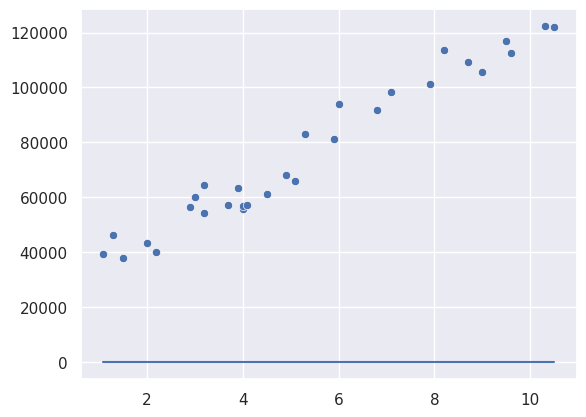

In [120]:
w = 0
b = 0

predictions = make_prediction(X,y,w = w,b = b)
# print(predictions)

sns.scatterplot(x= X , y = y)
plt.plot(X ,predictions)

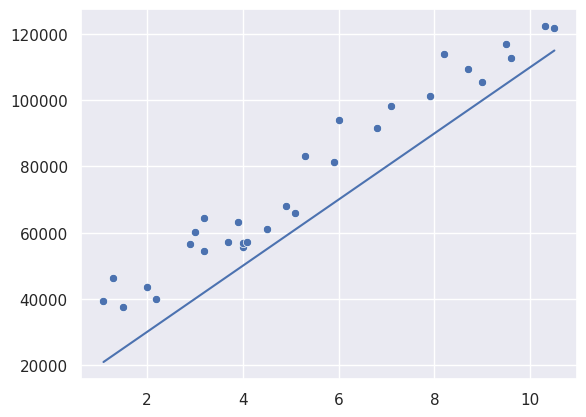

In [122]:
w = 10000
b = 10000

predictions = make_prediction(X,y,w = w,b = b)
# print(predictions)

sns.scatterplot(x= X , y = y)
plt.plot(X ,predictions)
plt.show()

In [123]:
def compute_cost(X, y, w, b) :

  """Calculates the Mean Squared Error (MSE) to measure model accuracy"""

  m = X.shape[0]
  cost = 0.0

  for i in range(m) :

    prediction = w * X[i] + b
    error = prediction - y[i]

    error_squared = error ** 2

    cost = cost + error_squared

  cost = cost / ( 2 * m )

  return cost

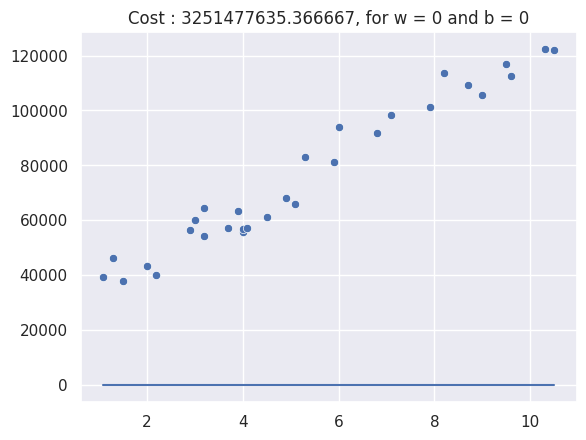

In [124]:
w = 0
b = 0

# Calculate predictions and evaluate cost manually

predictions = make_prediction(X, y, w = w, b = b)
# print(predictions)

sns.scatterplot(x = X , y = y)
plt.plot(X ,predictions)

# The title shows the cost, helping us see how 'wrong' our line is

plt.title(f'Cost : {compute_cost(X, y, w = w, b = b)}, for w = {w} and b = {b}')
plt.show()

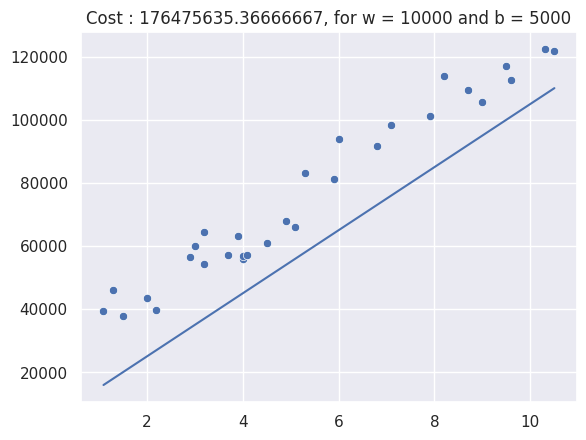

In [125]:
w = 10000
b = 5000

# Calculate predictions and evaluate cost manually

predictions = make_prediction(X, y, w = w, b = b)
# print(predictions)

sns.scatterplot(x = X , y = y)
plt.plot(X ,predictions)

# The title shows the cost, helping us see how 'wrong' our line is

plt.title(f'Cost : {compute_cost(X, y, w = w, b = b)}, for w = {w} and b = {b}')
plt.show()

In [126]:
# Gradient

def calculate_gradient( X, y, w, b ) :

  m = X.shape[0]

  dj_dw = 0.0
  dj_db = 0.0

  for i in range(m) :

    prediction = w * X[i] + b
    error = prediction - y[i]

    dj_dw = dj_dw + ( error * X[i] )
    dj_db = dj_db + error

  return dj_dw / m, dj_db / m



In [127]:
def gradient_descent( X, y, w_input, b_input, max_iter, alpha ) :

  w = w_input
  b = b_input

  cost_memo = []
  iteration = []

  for i in range(max_iter) :

    dj_dw, dj_db = calculate_gradient( X, y, w, b )

    w = w - alpha * dj_dw
    b = b - alpha * dj_db

    cost = compute_cost( X, y, w, b )

    cost_memo.append(cost)
    iteration.append(i)

  return w, b, cost_memo, iteration

In [128]:
w_final, b_final, cost_memo, iter_list = gradient_descent( X, y, w_input = 0, b_input = 0, max_iter = 1000, alpha = 0.01 )

In [129]:
print(f"Initial Cost : {cost_memo[0]:0.4f}")
print(f"Final Cost : {cost_memo[-1]:0.4f}")

print(f"Reduction : {(cost_memo[0] - cost_memo[-1]):0.4f}")

Initial Cost : 1344612525.8414
Final Cost : 16526873.1533
Reduction : 1328085652.6881


Text(0, 0.5, 'Cost')

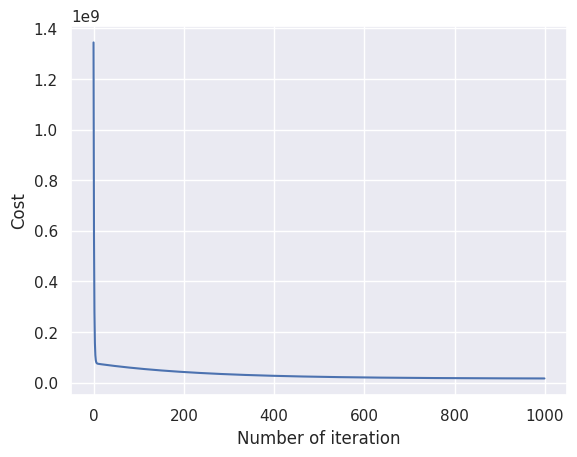

In [130]:
plt.plot(iter_list, cost_memo)
plt.xlabel('Number of iteration')
plt.ylabel('Cost')

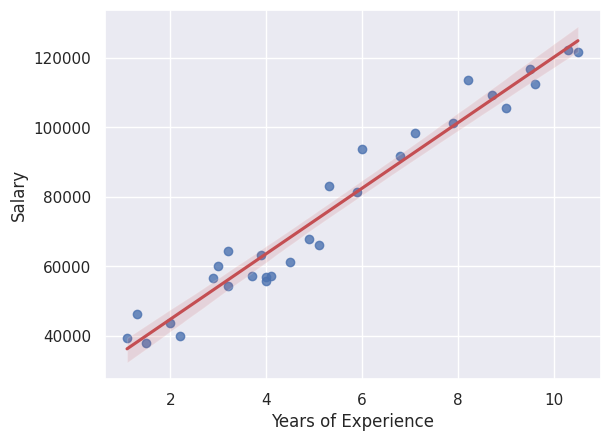

In [131]:
sns.regplot( x = X, y = y, line_kws=dict(color="r") )

plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.show()

## **Problem 5: Car Fuel Consumption Prediction**

**Dataset:  **
[<u>Auto MPG Dataset</u>](https://archive.ics.uci.edu/ml/datasets/auto+mpg?utm_source=chatgpt.com)

### **Tasks**

1.  Use horsepower to predict mpg.

2.  Implement MSE Cost Function manually.

3.  Apply Gradient Descent.

4.  Train for different learning rates:

    - 0.001

    - 0.01

    - 0.1

5.  Compare the convergence for different learning rates.

In [50]:
pip install ucimlrepo

In [132]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
auto_mpg = fetch_ucirepo(id=9)

# data (as pandas dataframes)
df = auto_mpg.data.original

In [133]:
df.isnull().sum()

,0
car_name,0
cylinders,0
displacement,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0
mpg,0


In [134]:
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].median())

X = df['horsepower'].values

y = df['mpg'].values

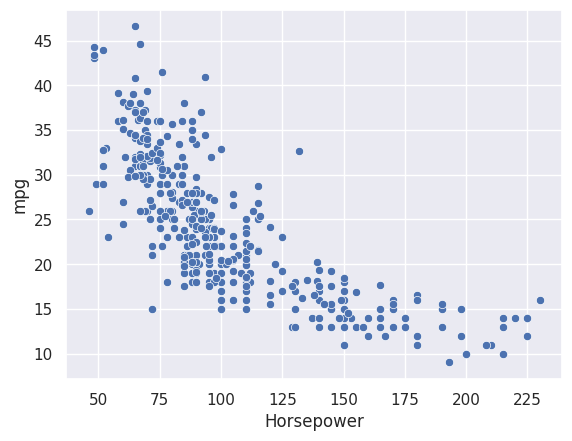

In [135]:
sns.scatterplot(x = X, y = y)

plt.xlabel('Horsepower')
plt.ylabel('mpg')
plt.show()

In [136]:
def make_prediction(X, y, w, b):
  """Calculates the model output: f(x) = wx + b"""

  m = X.shape[0] # Number of training examples
  pred_list = np.zeros((m,)) # Initialize an array to store results

  for i in range(m):
    # Apply the linear regression formula
    pred_list[i] = w * X[i] + b

  return pred_list

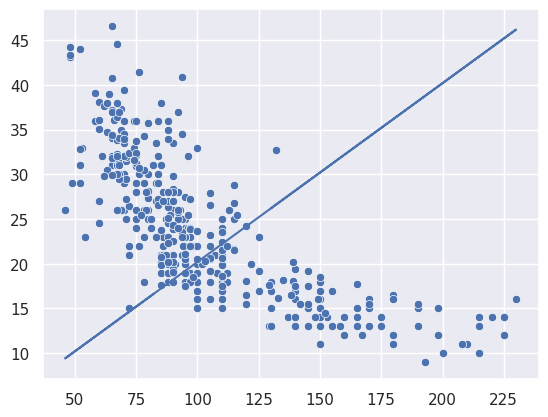

In [137]:
# Initial test with parameters w=0 and b=0
predictions = make_prediction(X, y, .2, .2)
# print(f"Predictions (0,0): {predictions}")

# Plot actual data vs initial predictions
sns.scatterplot(x=X, y=y)
plt.plot(X, predictions)
plt.show()

In [138]:
def compute_cost( X, y, w, b ) :

  m = X.shape[0]
  cost = 0.0

  for i in range(m) :

    prediction = w * X[i] + b
    error = prediction - y[i]

    error_squared = error ** 2
    cost = cost + error_squared

  cost = cost / (2 * m)
  return cost

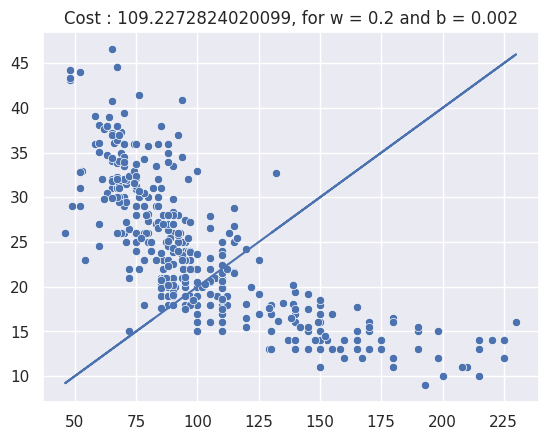

In [139]:
w = .2
b = .002

# Calculate predictions and evaluate cost manually

predictions = make_prediction(X, y, w = w, b = b)
# print(predictions)

sns.scatterplot(x= X , y = y)
plt.plot(X ,predictions)

# The title shows the cost, helping us see how 'wrong' our line is

plt.title(f'Cost : {compute_cost(X, y, w = w, b = b)}, for w = {w} and b = {b}')
plt.show()

In [140]:
# Gradient

def calculate_gradient(X, y, w, b) :

  m = X.shape[0]

  dj_dw = 0.0
  dj_db = 0.0

  for i in range(m) :

    prediction = w * X[i] + b
    error = prediction - y[i]

    dj_dw = dj_dw + ( error + X[i] )

    dj_db = dj_db + error

  return dj_dw / m, dj_db / m


In [141]:
# Gradient Descent

def gradient_descent(X, y, w_input, b_input, max_iter, alpha) :

  w = w_input
  b = b_input

  cost_memo = []
  iteration = []

  for i in range(max_iter) :

    dj_dw, dj_db = calculate_gradient(X, y, w, b)

    w = w - alpha * dj_dw
    b = b - alpha * dj_db

    cost = compute_cost(X, y, w, b)
    cost_memo.append(cost)
    iteration.append(i)

  return w, b, cost_memo, iteration


In [142]:
# Alpha = 0.001

w_final, b_final, cost_memo, iter_list = gradient_descent( X, y, w_input = 0, b_input = 0, max_iter = 1000, alpha = 0.001 )

print(f"Initial Cost : {cost_memo[0]:0.4f}")
print(f"Final Cost : {cost_memo[-1]:0.4f}")

print(f"Reduction : {(cost_memo[0] - cost_memo[-1]):0.4f}")

Initial Cost : 525.9735
Final Cost : 7191.5031
Reduction : -6665.5296


In [143]:
# Alpha = 0.01

w_final, b_final, cost_memo, iter_list = gradient_descent( X, y, w_input = 0, b_input = 0, max_iter = 1000, alpha = 0.01 )

print(f"Initial Cost : {cost_memo[0]:0.4f}")
print(f"Final Cost : {cost_memo[-1]:0.4f}")

print(f"Reduction : {(cost_memo[0] - cost_memo[-1]):0.4f}")

Initial Cost : 6102.9222
Final Cost : 85754.1620
Reduction : -79651.2398


In [144]:
# Alpha = 0.1

w_final, b_final, cost_memo, iter_list = gradient_descent( X, y, w_input = 0, b_input = 0, max_iter = 1000, alpha = 0.1 )

print(f"Initial Cost : {cost_memo[0]:0.4f}")
print(f"Final Cost : {cost_memo[-1]:0.4f}")

print(f"Reduction : {(cost_memo[0] - cost_memo[-1]):0.4f}")

/tmp/ipykernel_1239/2898332627.py:12: RuntimeWarning: overflow encountered in scalar add
  cost = cost + error_squared
/tmp/ipykernel_1239/2898332627.py:11: RuntimeWarning: overflow encountered in scalar power
  error_squared = error ** 2
/tmp/ipykernel_1239/2912666719.py:15: RuntimeWarning: overflow encountered in scalar add
  dj_dw = dj_dw + ( error + X[i] )
/tmp/ipykernel_1239/2912666719.py:17: RuntimeWarning: overflow encountered in scalar add
  dj_db = dj_db + error
/tmp/ipykernel_1239/229451604.py:15: RuntimeWarning: invalid value encountered in scalar subtract
  w = w - alpha * dj_dw
/tmp/ipykernel_1239/229451604.py:16: RuntimeWarning: invalid value encountered in scalar subtract
  b = b - alpha * dj_db


Initial Cost : 418827.5607
Final Cost : nan
Reduction : nan


## Comparison of Convergence for Different Learning Rates

The performance of Gradient Descent was tested using three different learning rates: 0.001, 0.01, and 0.1.

### α = 0.001
The cost decreased very slowly. The model showed stable behavior but required many iterations to converge. This indicates that the learning rate is too small, resulting in slow learning.

### α = 0.01
The cost increased instead of decreasing, showing that the model failed to converge. This suggests that the learning rate is too high for the given data scale, causing overshooting during updates.

### α = 0.1
The cost became unstable and resulted in overflow (NaN values). This indicates divergence, where the model parameters grow uncontrollably due to very large update steps.

---

## Summary Table

| Learning Rate | Behavior        | Result              |
|---------------|----------------|---------------------|
| 0.001         | Very slow      | Stable but slow     |
| 0.01          | Too large      | Divergence          |
| 0.1           | Very large     | Overflow / NaN      |

---

## Conclusion

Gradient Descent is highly sensitive to the learning rate. A small learning rate leads to slow convergence, while a large learning rate causes instability and divergence. Therefore, selecting an appropriate learning rate is crucial for successful model training.